In [1]:
# Sources and scope
from pathlib import Path
from os.path import relpath
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(root / "src"))
from garmin_central_overview import overview as ov  # noqa: E402
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 3)
data = ov.prepare(root)
display(data["provenance"].set_index("source"))

,value
source,
Notebooks reviewed,00–20
Features,private/comprehensive_features/features/eecf1da995c39b27
Classification,reports/comprehensive_features/818ddc22d6f28fdc
Latest full-block binary,reports/binary_6hour/11442e75c7e434aa
Timing / recording audit,reports/measurement_alignment/e5359ea4cc4b4efa
Execution,Read-only validation and summaries; no new fits or raw preprocessing


In [2]:
# Dataset overview
inventory = data["inventory"]
display(pd.DataFrame([
    ["Original EMA inventory (structural totals only)", 4680, 157, "115–137 raw fields by survey"],
    ["Development EMA / candidate matrix", 3706, 125, "678 candidates; 693 saved columns incl. metadata"],
    ["Development participants with Garmin", pd.NA, 123, "Two participants have no Garmin; their EMA rows remain"],
    ["Model cohort: valid score and context", 3689, 125, "438 supported candidates + context"],
], columns=["scope", "EMA rows", "participants", "dimensions / note"]).set_index("scope"))
display(data["sensors"].set_index("modality"))

,EMA rows,participants,dimensions / note
scope,,,
Original EMA inventory (structural totals only),4680,157,115–137 raw fields by survey
Development EMA / candidate matrix,3706,125,678 candidates; 693 saved columns incl. metadata
Development participants with Garmin,<NA>,123,Two participants have no Garmin; their EMA rows remain
Model cohort: valid score and context,3689,125,438 supported candidates + context


,physical_rows,logical_rows,duplicate_excess,participants,use
modality,,,,,
calories,650790,650760,30,123,Excluded
floorsClimbed,15176,15175,1,122,438 supported block
hr,15618530,15618282,248,123,438 supported block
ibi,34427546,34427074,472,123,Limited pilot only; no HRV predictors
intensityMinutes,17272,17270,2,119,Excluded
pulseOx,1471476,1471461,15,123,240 provisional; sensitivity only
steps,1063305,1063293,12,123,438 supported block
stress,4287943,4287874,69,123,Excluded


In [3]:
# Preprocessing and retained records
n = data["normalized"]
display(pd.DataFrame([
    ["Physical sensor records preserved", n["counts"]["physical_sensor_rows"], "No raw rows deleted"],
    ["Exact duplicate excess excluded from logical view", n["counts"]["exact_duplicate_excess_rows"], "Source records remain in physical tables"],
    ["Logical sensor records", n["counts"]["logical_sensor_rows"], "Repeated values at different times retained"],
    ["Conflict-flagged physical records", n["counts"]["conflicting_physical_rows"], "Retained and flagged; not a separate subtraction"],
    ["Mapped using mobile code", n["mapping_rows"]["content_mbl_cod"], "Verified crosswalk"],
    ["Mapped using respondent key", n["mapping_rows"]["content_rsp_id"], "Verified crosswalk"],
    ["Mapped using source content hash", n["mapping_rows"]["reference_content_hash"], "Verified crosswalk"],
    ["Development EMA rows retained", 3706, "One stable EMA key; original folds"],
    ["Missing composite; excluded only from modeling", data["missing_scores"], "All three valid 1–5 items required; no outcome imputation"],
], columns=["stage", "rows", "rule"]).set_index("stage"))

,rows,rule
stage,,
Physical sensor records preserved,57552038,No raw rows deleted
Exact duplicate excess excluded from logical view,849,Source records remain in physical tables
Logical sensor records,57551189,Repeated values at different times retained
Conflict-flagged physical records,6120,Retained and flagged; not a separate subtraction
Mapped using mobile code,50941979,Verified crosswalk
Mapped using respondent key,6271946,Verified crosswalk
Mapped using source content hash,338113,Verified crosswalk
Development EMA rows retained,3706,One stable EMA key; original folds
Missing composite; excluded only from modeling,17,All three valid 1–5 items required; no outcome imputation


In [4]:
# Clocks and feature acceptance
rules = [
    ["EMA UTC", "Actual local start minus row local-minus-UTC offset; 3,706 parsed"],
    ["Garmin UTC", "Unix ts unchanged; dte_tme retained separately; discrepancy flags preserved"],
    ["Minute start (1,868 EMAs)", "09:22 → cutoff 09:21 → [09:16, 09:21), synthetic example"],
    ["Second start (1,838 EMAs)", "09:22:35 → [09:17:35, 09:22:35), synthetic example"],
    ["Windows", "Left-inclusive, right-exclusive; 5, 15, 30, 60, 120, 360, 720, 1440 minutes"],
    ["HR", "30–240 bpm; conflicting timestamp groups / bad clocks excluded; no gap filling"],
    ["Mean / SD; slope", "≥2 readings and ≥1 s span; slope ≥3 readings and ≥60 s span"],
    ["Steps / floors", "Original adjacent counter pairs, no reset, gap ≤300 s; whole interval inside window"],
    ["History", "Earlier 24 h excluding current window; ≥30 observed UTC minutes across ≥3 hours"],
    ["PulseOx", "Provisional 70–100 percent-like values; separate sensitivity, not validated units"],
]
display(pd.DataFrame(rules, columns=["item", "implementation"]).set_index("item"))

,implementation
item,
EMA UTC,"Actual local start minus row local-minus-UTC offset; 3,706 parsed"
Garmin UTC,Unix ts unchanged; dte_tme retained separately; discrepancy flags preserved
"Minute start (1,868 EMAs)","09:22 → cutoff 09:21 → [09:16, 09:21), synthetic example"
"Second start (1,838 EMAs)","09:22:35 → [09:17:35, 09:22:35), synthetic example"
Windows,"Left-inclusive, right-exclusive; 5, 15, 30, 60, 120, 360, 720, 1440 minutes"
HR,30–240 bpm; conflicting timestamp groups / bad clocks excluded; no gap filling
Mean / SD; slope,≥2 readings and ≥1 s span; slope ≥3 readings and ≥60 s span
Steps / floors,"Original adjacent counter pairs, no reset, gap ≤300 s; whole interval inside window"
History,Earlier 24 h excluding current window; ≥30 observed UTC minutes across ≥3 hours


,features,responses,feature_cells,missing_cells,missing_pct
modality,,,,,
floors,56,3706,207536,163127,78.602
history,48,3706,177888,69290,38.951
hr,240,3706,889440,375591,42.228
interaction,24,3706,88944,65094,73.185
multiscale,14,3706,51884,29218,56.314
pulseox,240,3706,889440,500849,56.311
steps,56,3706,207536,107966,52.023


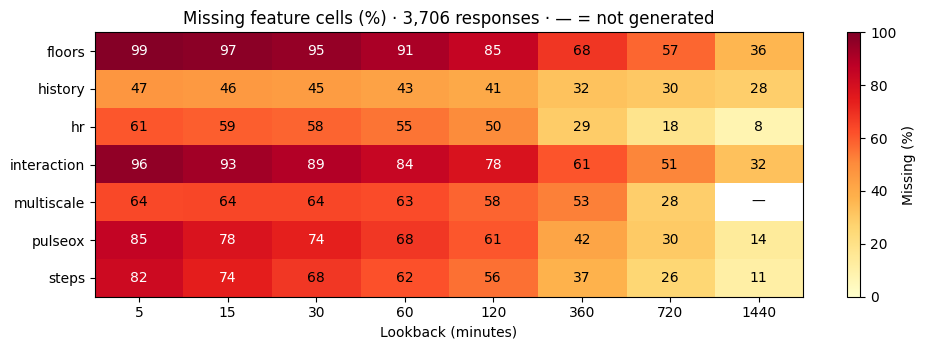

/Users/siddharthareddy/Desktop/Developer/GARMIN PROJECT/garmin-project/reports/central_research_overview/missingness_lookback.csv

In [5]:
# Missingness: feature cells, not unique responses
display(data["missing_modality"].set_index("modality"))
fig = ov.missing_plot(data)
display(fig)
plt.close(fig)
display(FileLink(relpath(root / ov.PUBLIC / "missingness_lookback.csv")))

In [6]:
# Complete feature inventory and per-feature missingness
features = data["dictionary"]
display(features.pivot_table(index=["status", "modality"], columns="lookback_minutes", values="name", aggfunc="count", fill_value=0))
examples = ["hr__mean__60m", "hr__sd__60m", "hr__latest__60m", "hr__slope__60m", "steps__added_supported__60m"]
display(features[features.name.isin(examples)][["name", "requirements", "responses", "missing_count", "missing_pct"]].set_index("name"))
display(features.groupby("modality").agg(candidate_columns=("name", "size"), distinct_statistics=("metric", "nunique")))
display(pd.DataFrame([
    ["Level / distribution", "mean, median, min/max, SD, variance, percentiles, range, IQR, MAD, CV"],
    ["Timing / change", "first/latest, slope, net/half-window change, original-adjacent changes"],
    ["Shape / observed bins", "skewness, excess kurtosis, observed-minute and rolling-five-minute summaries"],
    ["Activity / history", "supported counter increments, co-observed activity, earlier HR references / deviations"],
], columns=["statistic group", "examples"]).set_index("statistic group"))
display(FileLink(relpath(root / ov.PUBLIC / "complete_feature_inventory.csv")))

lookback_minutes                             5     15    30    60    120   \
status                          modality                                    
provisional_pulseox_sensitivity pulseox        30    30    30    30    30   
supported_observed_summary      floors          7     7     7     7     7   
                                history         6     6     6     6     6   
                                hr             30    30    30    30    30   
                                interaction     3     3     3     3     3   
                                multiscale      2     2     2     2     2   
                                steps           7     7     7     7     7   

lookback_minutes                             360   720   1440  
status                          modality                       
provisional_pulseox_sensitivity pulseox        30    30    30  
supported_observed_summary      floors          7     7     7  
                                history         6     6     6  
                                hr             30    30    30  
                                interaction     3     3     3  
                                multiscale      2     2     0  
                                steps           7     7     7

,requirements,responses,missing_count,missing_pct
name,,,,
hr__mean__60m,n>=2; span>=1s,3706,1992,53.751
hr__sd__60m,n>=2; span>=1s,3706,1992,53.751
hr__latest__60m,n>=1,3706,1981,53.454
hr__slope__60m,n>=3; span>=60s,3706,2063,55.666
steps__added_supported__60m,>=1 fully contained supported counter pairs; dt<=300s,3706,2296,61.954


,candidate_columns,distinct_statistics
modality,,
floors,56,7
history,48,6
hr,240,30
interaction,24,3
multiscale,14,2
pulseox,240,30
steps,56,7


,examples
statistic group,
Level / distribution,"mean, median, min/max, SD, variance, percentiles, range, IQR, MAD, CV"
Timing / change,"first/latest, slope, net/half-window change, original-adjacent changes"
Shape / observed bins,"skewness, excess kurtosis, observed-minute and rolling-five-minute summaries"
Activity / history,"supported counter increments, co-observed activity, earlier HR references / deviations"


/Users/siddharthareddy/Desktop/Developer/GARMIN PROJECT/garmin-project/reports/central_research_overview/complete_feature_inventory.csv

In [7]:
# Modeling matrix and actual training inputs
display(data["shapes"].set_index("dataset"))
display(pd.DataFrame({"complete cases across all 438": [data["complete_supported"]], "missing target": [data["missing_scores"]], "provisional columns in primary models": [0]}))
display(data["folds"][["fold", "training_rows", "validation_rows", "training_participants", "validation_participants", "retained_physiology", "context_numeric", "survey_encoded", "missing_indicators", "actual_inputs"]].set_index("fold"))
display(FileLink(relpath(root / ov.PUBLIC / "actual_model_inputs_by_fold.csv")))

,rows,columns
dataset,,
all development candidates,3706,678
supported candidate block,3706,438
provisional PulseOx block,3706,240
saved feature frame including metadata/context/targets,3706,693
valid outcome/context modeling rows,3689,438


,complete cases across all 438,missing target,provisional columns in primary models
0,1,17,0


,training_rows,validation_rows,training_participants,validation_participants,retained_physiology,context_numeric,survey_encoded,missing_indicators,actual_inputs
fold,,,,,,,,,
0,2948,741,100,25,438,2,3,438,881
1,2925,764,100,25,438,2,3,438,881
2,2945,744,100,25,438,2,3,438,881
3,2962,727,100,25,438,2,3,438,881
4,2976,713,100,25,437,2,3,438,880


/Users/siddharthareddy/Desktop/Developer/GARMIN PROJECT/garmin-project/reports/central_research_overview/actual_model_inputs_by_fold.csv

In [8]:
# Training-only preprocessing and nested tuning
display(pd.DataFrame([
    ["Split", "Five frozen participant folds; three grouped inner folds within each training fold"],
    ["Numeric inputs", "Drop training-all-missing / constant columns; training median imputation; StandardScaler"],
    ["Context", "Actual local time sine/cosine + training-fitted survey one-hot encoder"],
    ["Missingness", "Training-variable missingness flags; separate from physiological measurements"],
    ["Logistic regression (13)", "L2; C ∈ {0.01, 0.1, 1, 10}; select inner macro F1; no outer-fold selection"],
    ["Selection comparisons", "Training-only correlation >0.95 filtering, L1 / elastic regularization; separate branches"],
    ["Binary follow-up (15)", "Same full block; inner AUROC selection; separate from Notebook 13's objective"],
    ["This overview", "Reuses saved fits; recomputes metrics; no new model search"],
], columns=["step", "implementation"]).set_index("step"))
display(data["folds"][["fold", "selected_C", "dropped_numeric"]].set_index("fold"))

,implementation
step,
Split,Five frozen participant folds; three grouped inner folds within each training fold
Numeric inputs,Drop training-all-missing / constant columns; training median imputation; StandardScaler
Context,Actual local time sine/cosine + training-fitted survey one-hot encoder
Missingness,Training-variable missingness flags; separate from physiological measurements
Logistic regression (13),"L2; C ∈ {0.01, 0.1, 1, 10}; select inner macro F1; no outer-fold selection"
Selection comparisons,"Training-only correlation >0.95 filtering, L1 / elastic regularization; separate branches"
Binary follow-up (15),Same full block; inner AUROC selection; separate from Notebook 13's objective
This overview,Reuses saved fits; recomputes metrics; no new model search


,selected_C,dropped_numeric
fold,,
0,10,0
1,10,0
2,10,0
3,10,0
4,10,1


In [9]:
# Score labels and train / held-out development class support
display(pd.DataFrame([
    ["Composite", "nervous + (6 − cope) + (6 − control); integer 3–15; all three valid items"],
    ["Three classes", "0: 3–4; 1: 5–9; 2: 10–15"],
    ["Binary tasks", "≥5 versus ≤4; ≥10 versus ≤9; exploratory, not clinical diagnoses"],
    ["Validation", "Held-out development participants, not the sealed final test"],
], columns=["item", "definition"]).set_index("item"))
display(data["support"])
display(data["support"].filter(like="validation").sum().rename("pooled OOF support").to_frame())

,definition
item,
Composite,nervous + (6 − cope) + (6 − control); integer 3–15; all three valid items
Three classes,0: 3–4; 1: 5–9; 2: 10–15
Binary tasks,"≥5 versus ≤4; ≥10 versus ≤9; exploratory, not clinical diagnoses"
Validation,"Held-out development participants, not the sealed final test"


,training class 0,training class 1,training class 2,validation class 0,validation class 1,validation class 2
fold,,,,,,
0,799,1739,410,234,402,105
1,829,1698,398,204,443,117
2,894,1637,414,139,504,101
3,805,1758,399,228,383,116
4,805,1732,439,228,409,76


,pooled OOF support
validation class 0,1033
validation class 1,2141
validation class 2,515


,responses,participants,macro AUROC (OvR),macro_f1,balanced_accuracy,elevated_precision,elevated_recall
view,,,,,,,
context,3689,125,0.472,0.245,0.333,0.000,0.000
dummy_majority,3689,125,0.500,0.245,0.333,0.000,0.000
full,3689,125,0.499,0.335,0.338,0.130,0.109
full_corr,3689,125,0.496,0.319,0.326,0.120,0.080
full_elastic,3689,125,0.493,0.313,0.330,0.153,0.056
full_l1,3689,125,0.492,0.315,0.334,0.173,0.056
original60,3689,125,0.483,0.245,0.333,0.000,0.000


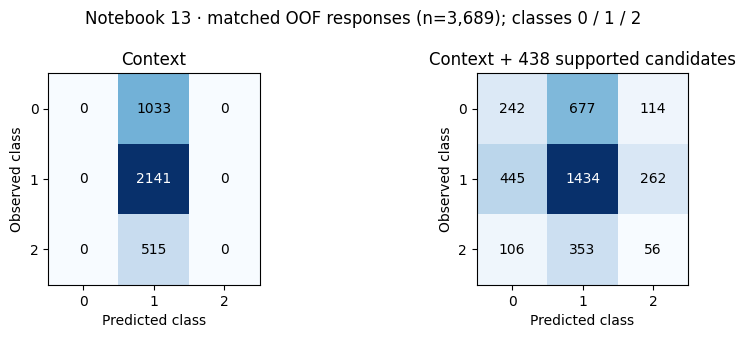

In [10]:
# Three-class classification: matched 3,689 responses / 125 participants
metrics = ["roc_auc", "macro_f1", "balanced_accuracy", "elevated_precision", "elevated_recall"]
display(data["comparisons"][["view", "responses", "participants"] + metrics].set_index("view").rename(columns={"roc_auc": "macro AUROC (OvR)"}))
fig = ov.confusion_plot(data)
display(fig)
plt.close(fig)

In [11]:
# Binary classification and matched uncertainty
binary = data["metrics"].query('task != "three_class"')
display(binary[["checkpoint", "task", "view"] + metrics].set_index(["checkpoint", "task", "view"]))
display(data["paired"][["task", "roc_auc_difference", "roc_auc_low", "roc_auc_high", "macro_f1_difference", "macro_f1_low", "macro_f1_high"]].set_index("task"))
display(pd.DataFrame({"reading": ["A = ≥5; B = ≥10. All rows use 3,689 responses / 125 participants.", "Paired 95% participant-bootstrap intervals: full minus context, Notebook 13.", "F1 gains do not establish useful ranking: AUROC difference intervals include zero.", "Intervals condition on fixed OOF predictions and repeated exploratory development."]}))

roc_auc  macro_f1  balanced_accuracy  \
checkpoint task        view                                                 
13         at_least_10 context         0.497     0.462              0.500   
                       full            0.477     0.501              0.505   
           at_least_5  context         0.471     0.419              0.500   
                       full            0.525     0.502              0.509   
15         A           context_u       0.479     0.419              0.500   
                       multiscale_u    0.519     0.456              0.493   
           B           context_u       0.513     0.462              0.500   
                       multiscale_u    0.482     0.494              0.509   

                                     elevated_precision  elevated_recall  
checkpoint task        view                                               
13         at_least_10 context                    0.000            0.000  
                       full                       0.155            0.085  
           at_least_5  context                    0.720            1.000  
                       full                       0.725            0.839  
15         A           context_u                  0.720            1.000  
                       multiscale_u               0.717            0.918  
           B           context_u                  0.000            0.000  
                       multiscale_u               0.213            0.045

,roc_auc_difference,roc_auc_low,roc_auc_high,macro_f1_difference,macro_f1_low,macro_f1_high
task,,,,,,
three_class,0.027,-0.006,0.062,0.091,0.071,0.110
at_least_5,0.054,-0.002,0.108,0.083,0.060,0.104
at_least_10,-0.020,-0.066,0.024,0.039,0.018,0.059


,reading
0,"A = ≥5; B = ≥10. All rows use 3,689 responses / 125 participants."
1,"Paired 95% participant-bootstrap intervals: full minus context, Notebook 13."
2,F1 gains do not establish useful ranking: AUROC difference intervals include zero.
3,Intervals condition on fixed OOF predictions and repeated exploratory development.


In [12]:
# Earlier boosting comparison: separate matched cohort, not a ranking against Notebook 13
display(data["earlier"][["model", "view", "responses", "participants"] + metrics].set_index(["model", "view"]))
display(pd.DataFrame({"scope": ["Notebook 12: 60-minute complete cases, 1,355 responses / 113 participants.", "Only original HR + steps + context; boosting was not fitted to all 438 here.", "Compare models within this table; do not compare their scores directly with the 3,689-row cohort."]}))

,,responses,participants,roc_auc,macro_f1,balanced_accuracy,elevated_precision,elevated_recall
model,view,,,,,,,
lightgbm,context_hr_steps,1355,113,0.469,0.311,0.338,0.111,0.012
logistic,context_hr_steps,1355,113,0.464,0.251,0.334,0.000,0.000
xgboost,context_hr_steps,1355,113,0.465,0.306,0.335,0.273,0.018
dummy,dummy,1355,113,0.500,0.249,0.333,0.000,0.000


,scope
0,"Notebook 12: 60-minute complete cases, 1,355 responses / 113 participants."
1,Only original HR + steps + context; boosting was not fitted to all 438 here.
2,"Compare models within this table; do not compare their scores directly with the 3,689-row cohort."


In [13]:
# Continuous-score results: same 3,689 responses / 125 participants
regression = pd.read_csv(root / ov.REVIEW / "regression_metrics.csv")
display(regression.pivot(index="family", columns="view", values="mae").rename_axis(columns="Notebook 14 · OOF MAE"))
display(pd.DataFrame({"interpretation": ["Full = context + 438 supported candidates; no stable improvement over matching median baseline.", "Within-person score variation is not evidence that wearable measurements predict that variation."]}))

Notebook 14 · OOF MAE,context,dummy,full
family,,,
elastic,2.239,NaN,2.245
hgb,2.214,NaN,2.255
huber,2.224,NaN,2.314
lasso,2.240,NaN,2.247
lgbm,2.252,NaN,2.260
mean,NaN,2.245,NaN
median,NaN,2.209,NaN
ridge,2.239,NaN,2.278
xgb,2.230,NaN,2.246


,interpretation
0,Full = context + 438 supported candidates; no stable improvement over matching median baseline.
1,Within-person score variation is not evidence that wearable measurements predict that variation.


In [14]:
# Recording support and remaining limitations
coverage = data["coverage"].copy()
coverage["accepted_pct"] = 100 * coverage.any_accepted / coverage.responses
coverage["occupied_minute_pct_median"] = 100 * coverage.occupied_fraction_median
display(coverage[["lookback_minutes", "responses", "any_recorded", "any_accepted", "accepted_pct", "occupied_minute_pct_median", "gap_median_seconds", "freshness_median_seconds"]].set_index("lookback_minutes"))
display(pd.DataFrame([
    ["Recording support", "Any reading is not full-window coverage; no interpolation or carry-forward"],
    ["Gap / freshness medians", "Maximum gaps include window edges / empty windows; freshness excludes no-reading rows"],
    ["Missingness", "Median-filled features / missingness flags may reflect recording patterns, not physiology"],
    ["Timing", "Acquisition versus receipt/batching remains unknown; no validated real-time claim"],
    ["Recall", "Morning: since waking; Midday/Endday: since last prompt. Delivery logs unavailable"],
    ["IBI / HRV", "Limited ≥240 s run pilot only; normal-beat status unverified; not among 678 predictors"],
    ["Next evidence", "Collector/SDK version, original payloads, acquisition/receipt clocks, prompt logs, quality flags"],
], columns=["limitation", "status"]).set_index("limitation"))

,responses,any_recorded,any_accepted,accepted_pct,occupied_minute_pct_median,gap_median_seconds,freshness_median_seconds
lookback_minutes,,,,,,,
5,3706,1520,1498,40.421,0.000,300.000,0.778
15,3706,1598,1554,41.932,0.000,900.000,0.808
30,3706,1663,1610,43.443,0.000,1800.000,0.832
60,3706,1797,1725,46.546,0.000,3600.000,0.910
120,3706,1979,1897,51.187,0.833,7171.070,1.020
360,3706,2790,2693,72.666,16.111,12703.872,2.802
720,3706,3219,3098,83.594,15.694,26660.724,871.991
1440,3706,3539,3464,93.470,22.917,42830.757,3757.870


,status
limitation,
Recording support,Any reading is not full-window coverage; no interpolation or carry-forward
Gap / freshness medians,Maximum gaps include window edges / empty windows; freshness excludes no-reading rows
Missingness,"Median-filled features / missingness flags may reflect recording patterns, not physiology"
Timing,Acquisition versus receipt/batching remains unknown; no validated real-time claim
Recall,Morning: since waking; Midday/Endday: since last prompt. Delivery logs unavailable
IBI / HRV,Limited ≥240 s run pilot only; normal-beat status unverified; not among 678 predictors
Next evidence,"Collector/SDK version, original payloads, acquisition/receipt clocks, prompt logs, quality flags"


In [15]:
# Verification
from garmin_central_overview.verify import verify_inputs
display(pd.Series(verify_inputs(root, data["checks"]), name="verified").to_frame())

,verified
previous_files_checked,1308
documented_maintenance_exceptions,3
prior_review_sealed_files,46
raw_reference_metadata_unchanged,7870
earlier_bundle_manifests_preserved,3246
development_rows,3706
development_participants,125
modeling_rows,3689
candidate_columns,678
supported_columns,438
